## import libraries

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import joblib

sns.set_style("whitegrid")

## load dataset

In [53]:


df = pd.read_csv("ayursutra_advanced_dataset_2000_records.csv")

df.head() 

,Age,Gender,Symptom,Disease,Condition_Type,Severity_Level,Duration_in_days,Previous_Therapy,Response_to_Previous,Lifestyle_Factor,Therapy
0,49,Female,Knee Pain,Osteoarthritis,Chronic,Mild,225,Shirodhara,Improved,Active,Janu Basti
1,69,Female,Weight Gain,Obesity,Acute,Moderate,234,Kati Basti,No Change,Stressful,Udvartana
2,60,Male,High BP,Hypertension,Acute,Mild,106,Abhyanga,No Change,Stressful,Nasya
3,25,Female,High Sugar,Diabetes Mellitus,Chronic,Moderate,12,Vamana,No Change,Stressful,Udvartana
4,36,Male,Low Mood,Depression,Chronic,Mild,281,Vamana,Worsened,Stressful,Virechana


## data overview

In [13]:
df.info()
df.describe()
df["Therapy"].value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Age                   2000 non-null   int64
 1   Gender                2000 non-null   str  
 2   Symptom               2000 non-null   str  
 3   Disease               2000 non-null   str  
 4   Condition_Type        2000 non-null   str  
 5   Severity_Level        2000 non-null   str  
 6   Duration_in_days      2000 non-null   int64
 7   Previous_Therapy      2000 non-null   str  
 8   Response_to_Previous  2000 non-null   str  
 9   Lifestyle_Factor      2000 non-null   str  
 10  Therapy               2000 non-null   str  
dtypes: int64(2), str(9)
memory usage: 172.0 KB


Therapy
Shirodhara    306
Nasya         300
Virechana     286
Abhyanga      252
Janu Basti    157
Takradhara    155
Udvartana     142
Vamana        141
Basti         131
Kati Basti    130
Name: count, dtype: int64

## check missing values

In [14]:
df.isnull().sum()

Age                     0
Gender                  0
Symptom                 0
Disease                 0
Condition_Type          0
Severity_Level          0
Duration_in_days        0
Previous_Therapy        0
Response_to_Previous    0
Lifestyle_Factor        0
Therapy                 0
dtype: int64

In [15]:
df = df.dropna()

## Exploratory Data Analysis

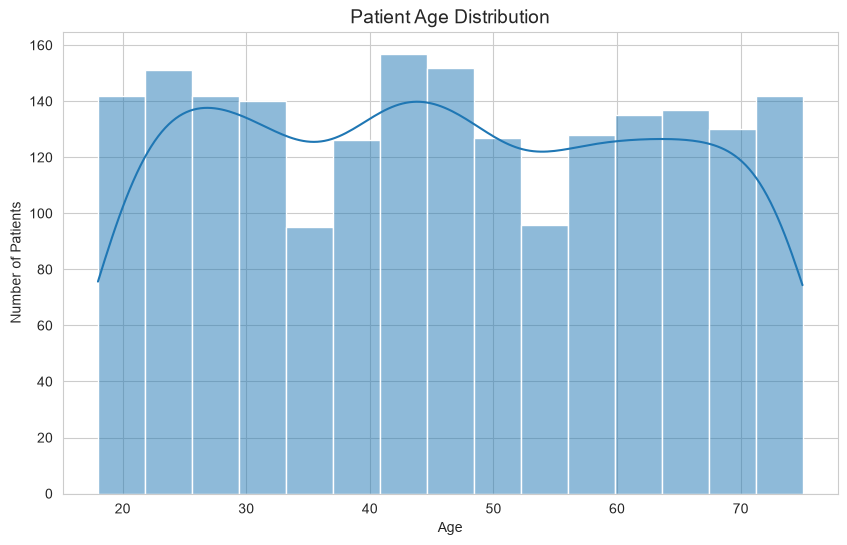

In [16]:
# age distribution
plt.figure(figsize=(10,6))

sns.histplot(df["Age"], bins=15, kde=True)

plt.title("Patient Age Distribution", fontsize=14)
plt.xlabel("Age")
plt.ylabel("Number of Patients")

plt.show()

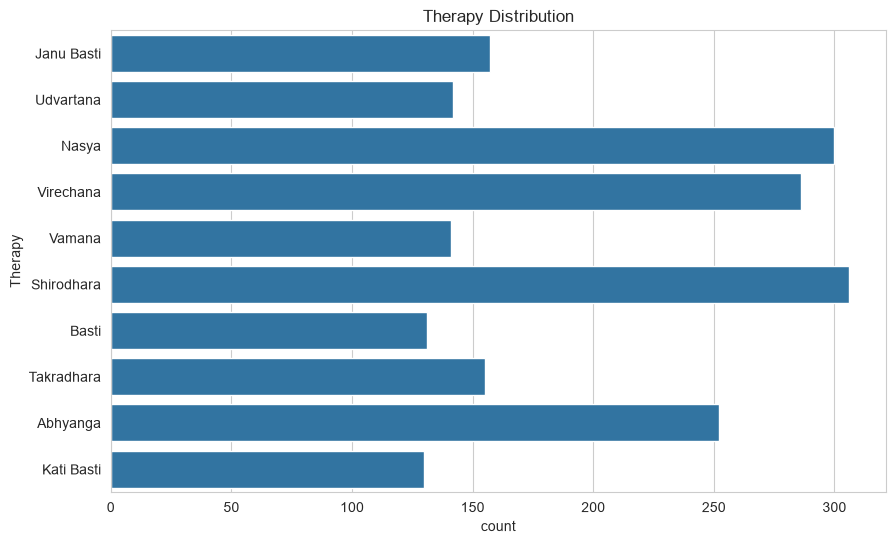

In [17]:
# therapy distribution
plt.figure(figsize=(10,6))
sns.countplot(y="Therapy", data=df)  # it counts ho many times each catagory appears
plt.title("Therapy Distribution")
plt.show()

## Disease vs Therapy

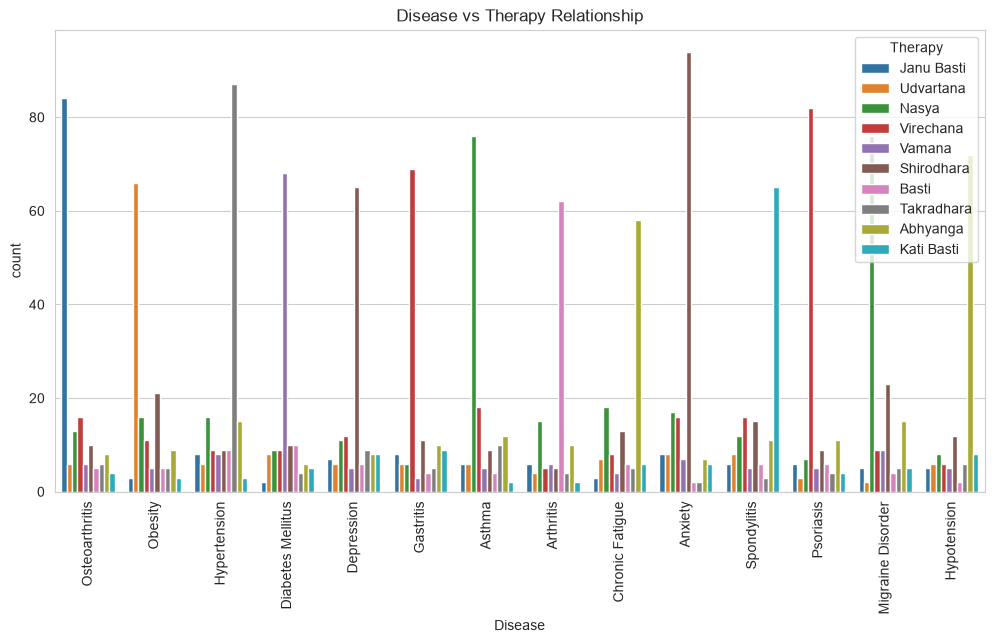

In [18]:
plt.figure(figsize=(12,6))

sns.countplot(
    x="Disease",
    hue="Therapy",
    data=df
)

plt.xticks(rotation=90)
plt.title("Disease vs Therapy Relationship")
plt.show()

## Severity Level vs Therapy

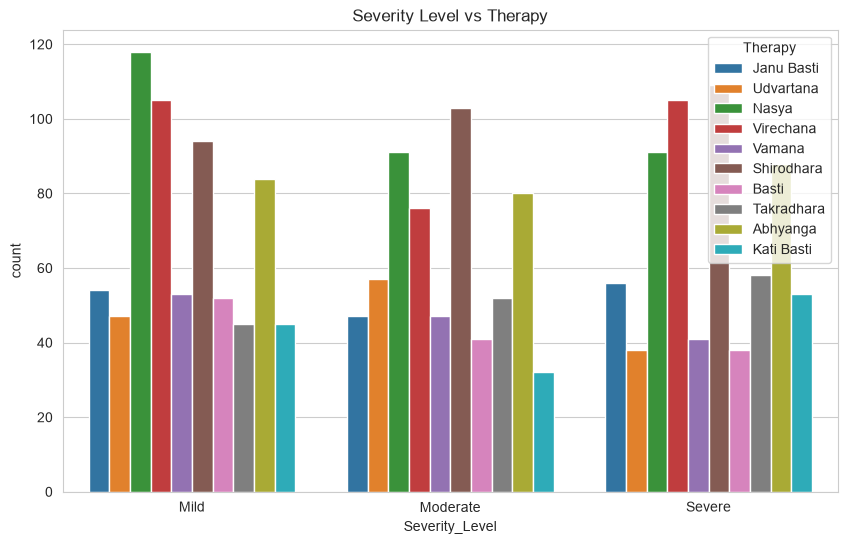

In [19]:
plt.figure(figsize=(10,6))

sns.countplot(
    x="Severity_Level",
    hue="Therapy",
    data=df
)

plt.title("Severity Level vs Therapy")
plt.show()

## Condition Type vs Therapy

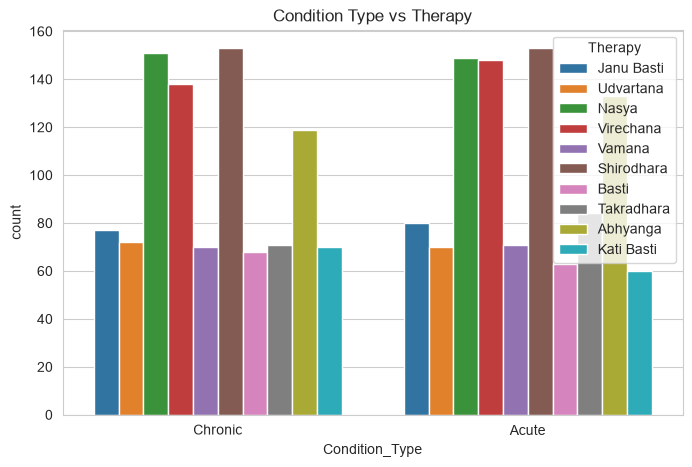

In [20]:
plt.figure(figsize=(8,5))

sns.countplot(
    x="Condition_Type",
    hue="Therapy",
    data=df
)

plt.title("Condition Type vs Therapy")
plt.show()

## Duration vs Therapy

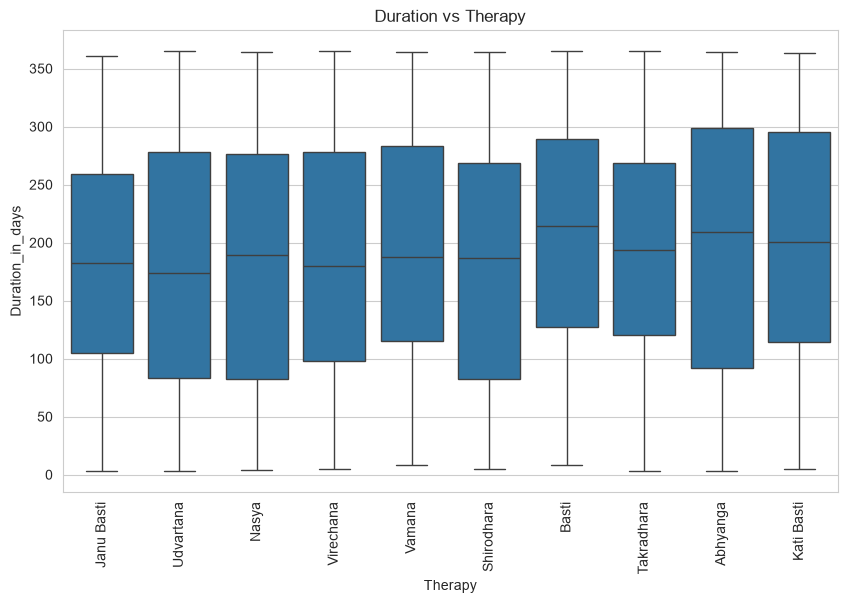

In [21]:
plt.figure(figsize=(10,6))

sns.boxplot(
    x="Therapy",
    y="Duration_in_days",
    data=df
)

plt.xticks(rotation=90)
plt.title("Duration vs Therapy")
plt.show()

## Previous Therapy Response vs New Therapy

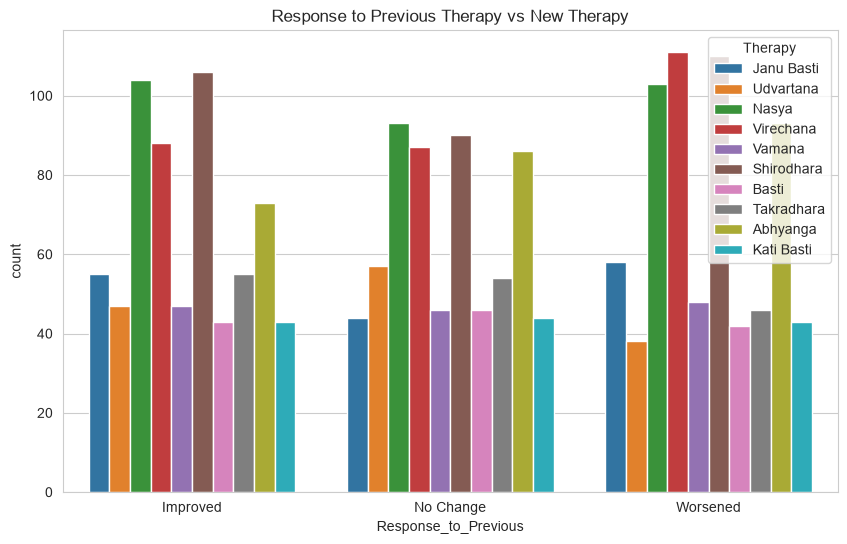

In [22]:
plt.figure(figsize=(10,6))

sns.countplot(
    x="Response_to_Previous",
    hue="Therapy",
    data=df
)

plt.title("Response to Previous Therapy vs New Therapy")
plt.show()

## Lifestyle Factor vs Therapy

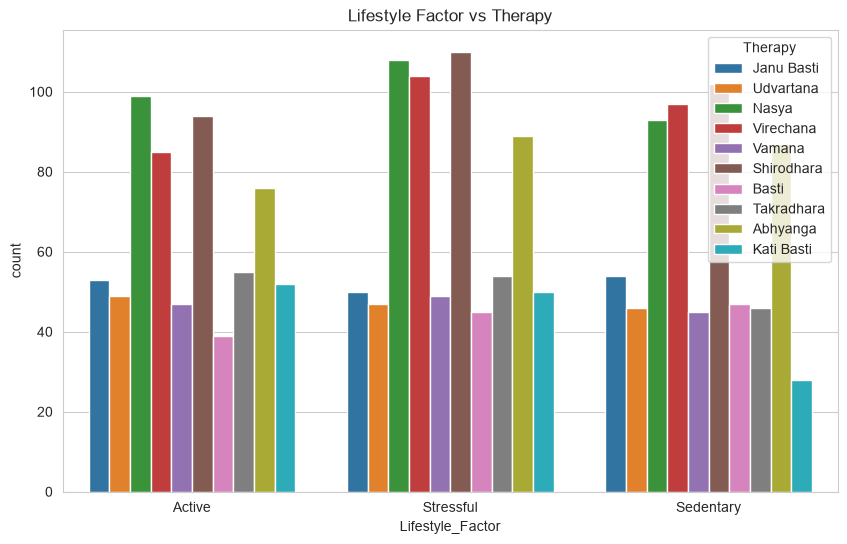

In [23]:
plt.figure(figsize=(10,6))

sns.countplot(
    x="Lifestyle_Factor",
    hue="Therapy",
    data=df
)

plt.title("Lifestyle Factor vs Therapy")
plt.show()

## Correlation Heatmap

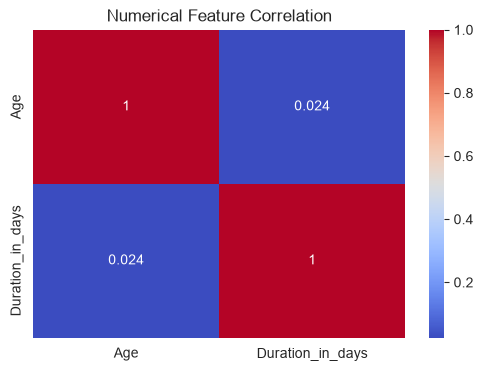

In [24]:
plt.figure(figsize=(6,4))

sns.heatmap(df[["Age","Duration_in_days"]].corr(),
            annot=True,
            cmap="coolwarm")

plt.title("Numerical Feature Correlation")
plt.show()

#Red → strong positive correlation
#Blue → weak/negative correlation

## Separate Features & Target

In [25]:
X = df.drop("Therapy", axis=1) #Patient information
y = df["Therapy"]   #Therapy to predict

## Define Feature Types

In [26]:
categorical_features = [
    "Gender", 
    "Symptom", 
    "Disease", 
    "Condition_Type",
    "Severity_Level",
    "Previous_Therapy",
    "Response_to_Previous",
    "Lifestyle_Factor"
]

numerical_features = [
    "Age",
    "Duration_in_days"
]

## Build Preprocessing Pipeline

In [27]:
# it converts all  type of input data into numerical array value.eg-Gender = Male,Male → [1,0]
preprocessor = ColumnTransformer(   
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

#ColumnTransformer-->Numerical data needs scaling and Categorical data needs encoding
#StandardScaler-->Xscaled =X−mean/std
#OneHotEncoding-->Converts category → binary columns


## Build Full ML Pipeline

In [28]:
model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=15,
        random_state=42
    ))
])

#PIPELINE-->Pipeline connects steps sequentially.
#Input → Cleaning → Conversion → Model → Prediction
#User Input
    # ↓
#Preprocessing
    # ↓
#Random Forest
   #  ↓
#Prediction


## Train Test Split

In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Train Model

In [30]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](10,)","['Abhyanga','Basti','Janu Basti',...,'Udvartana','Vamana','Virechana']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['Age','Gender','Symptom',...,'Previous_Therapy','Response_to_Previous', 'Lifestyle_Factor']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifi

## Evaluate Model

In [31]:
y_pred = model.predict(X_test)

accuracy_before= accuracy_score(y_test, y_pred)
print(" Accuracy BEFORE Hyperparameter Tuning:",
      round(accuracy_before))

#Accuracy =CorrectPredictions/total prediction
print("\nClassification Report:\n")

print(classification_report(y_test, y_pred))

#Precision=Correct Predictions/total prediction
#Recall=Correctly Found/actual cases
#F1-Score=harmonic mean(precision,recall)

 Accuracy BEFORE Hyperparameter Tuning: 1

Classification Report:

              precision    recall  f1-score   support

    Abhyanga       0.51      0.46      0.48        50
       Basti       0.56      0.36      0.43        28
  Janu Basti       0.45      0.42      0.43        31
  Kati Basti       0.67      0.56      0.61        25
       Nasya       0.47      0.51      0.49        73
  Shirodhara       0.46      0.59      0.52        56
  Takradhara       0.67      0.55      0.60        33
   Udvartana       0.47      0.39      0.43        23
      Vamana       0.58      0.48      0.53        29
   Virechana       0.52      0.67      0.59        52

    accuracy                           0.52       400
   macro avg       0.54      0.50      0.51       400
weighted avg       0.52      0.52      0.51       400



## Confusion Matrix

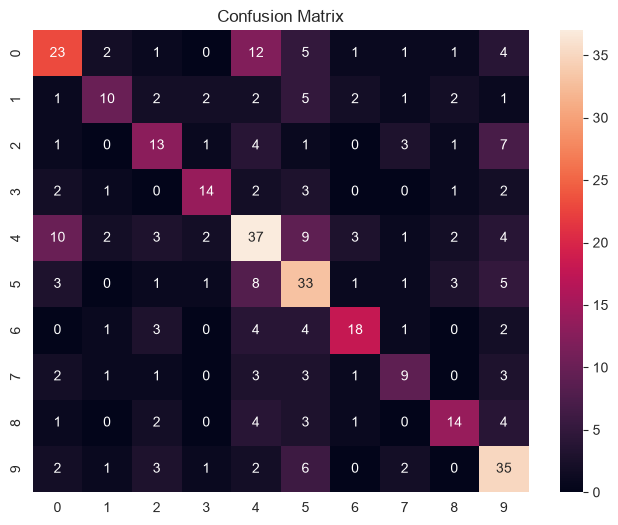

In [32]:
plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d")
plt.title("Confusion Matrix")
plt.show()

#The confusion matrix visualizes the classification performance by comparing actual and predicted therapy classes. Higher values along the diagonal indicate correct therapy predictions, while off-diagonal values reveal misclassification patterns between clinically similar therapies.

## Hyperparameter Tuning

In [33]:
param_grid = {
    "classifier__n_estimators":[100,200,300],
    "classifier__max_depth":[10,20,None],
    "classifier__max_features":["sqrt","log2"],
    "classifier__min_samples_leaf":[1,2,4],
    "classifier__bootstrap":[True,False]
}

In [34]:
grid_search = GridSearchCV(
    model,
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=2
)

In [35]:
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 108 candidates, totalling 540 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__bootstrap': [True, False], 'classifier__max_depth': [10, 20, ...], 'classifier__max_features': ['sqrt', 'log2'], 'classifier__min_samples_leaf': [1, 2, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more abo

In [36]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross Validation Accuracy:")
print(grid_search.best_score_)

Best Parameters:
{'classifier__bootstrap': False, 'classifier__max_depth': None, 'classifier__max_features': 'log2', 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 200}

Best Cross Validation Accuracy:
0.53125


In [37]:
best_model = grid_search.best_estimator_

In [38]:
y_pred_tuned = best_model.predict(X_test)

accuracy_after = accuracy_score(y_test, y_pred_tuned)

print(" Accuracy :",
      round(accuracy_after,4))

 Accuracy : 0.525


In [39]:
print(classification_report(y_test, y_pred_tuned))

              precision    recall  f1-score   support

    Abhyanga       0.50      0.46      0.48        50
       Basti       0.50      0.36      0.42        28
  Janu Basti       0.42      0.42      0.42        31
  Kati Basti       0.82      0.56      0.67        25
       Nasya       0.50      0.51      0.50        73
  Shirodhara       0.50      0.64      0.56        56
  Takradhara       0.60      0.55      0.57        33
   Udvartana       0.50      0.39      0.44        23
      Vamana       0.54      0.48      0.51        29
   Virechana       0.55      0.69      0.61        52

    accuracy                           0.53       400
   macro avg       0.54      0.51      0.52       400
weighted avg       0.53      0.53      0.52       400



In [40]:


# Get unique therapy labels
labels = np.unique(y_test)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_tuned, labels=labels)

# Store results
class_accuracy = {}

for i, label in enumerate(labels):
    TP = cm[i, i]
    FN = sum(cm[i, :]) - TP
    FP = sum(cm[:, i]) - TP
    TN = np.sum(cm) - (TP + FP + FN)
    
    accuracy = (TP + TN) / (TP + TN + FP + FN)
    class_accuracy[label] = accuracy

# Convert to DataFrame for better view
accuracy_df = pd.DataFrame(list(class_accuracy.items()), columns=["Therapy", "Accuracy"])

print(accuracy_df)

      Therapy  Accuracy
0    Abhyanga    0.8750
1       Basti    0.9300
2  Janu Basti    0.9100
3  Kati Basti    0.9650
4       Nasya    0.8175
5  Shirodhara    0.8600
6  Takradhara    0.9325
7   Udvartana    0.9425
8      Vamana    0.9325
9   Virechana    0.8850


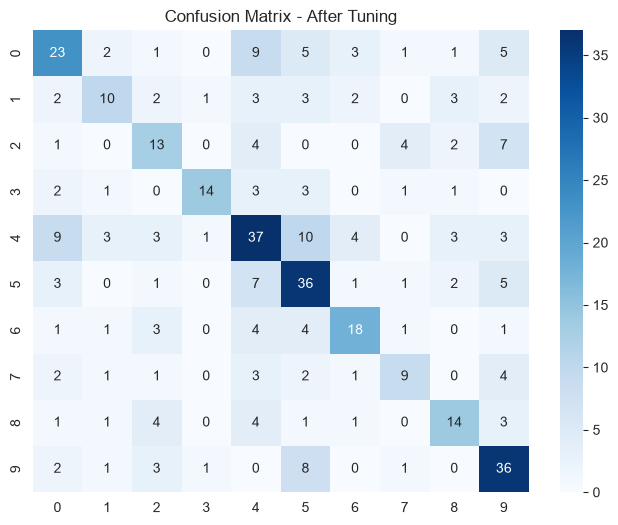

In [41]:
plt.figure(figsize=(8,6))

sns.heatmap(
    confusion_matrix(y_test, y_pred_tuned),
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix - After Tuning")
plt.show()

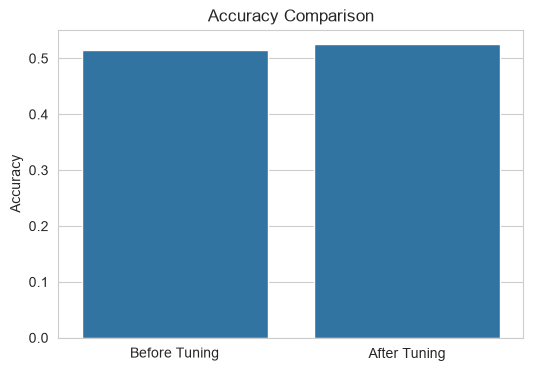

In [42]:
plt.figure(figsize=(6,4))

models = ["Before Tuning","After Tuning"]
scores = [accuracy_before, accuracy_after]

sns.barplot(x=models,y=scores)

plt.title("Accuracy Comparison")
plt.ylabel("Accuracy")

plt.show()

In [43]:
import pandas as pd

# -------- Therapy Prediction Function --------
def predict_therapy(
    age,
    duration_in_days,
    gender,
    symptom,
    disease,
    condition_type,
    severity_level,
    previous_therapy,
    response_to_previous,
    lifestyle_factor,
    model=best_model   # use tuned model
):
    
    # Create input dictionary
    patient_data = {
        "Age": age,
        "Duration_in_days": duration_in_days,
        "Gender": gender,
        "Symptom": symptom,
        "Disease": disease,
        "Condition_Type": condition_type,
        "Severity_Level": severity_level,
        "Previous_Therapy": previous_therapy,
        "Response_to_Previous": response_to_previous,
        "Lifestyle_Factor": lifestyle_factor
    }

    # Convert to DataFrame
    input_df = pd.DataFrame([patient_data])

    # Prediction
    predicted_therapy = model.predict(input_df)[0]

    # Probability (optional)
    confidence = max(model.predict_proba(input_df)[0])

    print(" Recommended Therapy:", predicted_therapy)
    # print(" Confidence Score:", round(confidence * 100, 2), "%")

    return predicted_therapy

In [44]:
predict_therapy(
    age=45,
    duration_in_days=30,
    gender="Male",
    symptom="Joint Pain",
    disease="Arthritis",
    condition_type="Chronic",
    severity_level="Moderate",
    previous_therapy="Abhyanga",
    response_to_previous="Partial",
    lifestyle_factor="Sedentary"
)

 Recommended Therapy: Basti


'Basti'

In [45]:
predict_therapy(
    age=32,
    duration_in_days=15,
    gender="Female",
    symptom="Indigestion",
    disease="Gastritis",
    condition_type="Acute",
    severity_level="Moderate",
    previous_therapy="None",
    response_to_previous="None",
    lifestyle_factor="Irregular Diet"
)

 Recommended Therapy: Virechana


'Virechana'

In [46]:
predict_therapy(
    age=28,
    duration_in_days=20,
    gender="Male",
    symptom="Breathing Difficulty",
    disease="Asthma",
    condition_type="Chronic",
    severity_level="Severe",
    previous_therapy="Steam Therapy",
    response_to_previous="Partial",
    lifestyle_factor="Dust Exposure"
)

 Recommended Therapy: Nasya


'Nasya'

In [47]:
predict_therapy(
    age=40,
    duration_in_days=60,
    gender="Female",
    symptom="Stress",
    disease="Anxiety",
    condition_type="Chronic",
    severity_level="Moderate",
    previous_therapy="Meditation",
    response_to_previous="Temporary Relief",
    lifestyle_factor="High Work Stress"
)

 Recommended Therapy: Shirodhara


'Shirodhara'

In [48]:
predict_therapy(
    age=55,
    duration_in_days=90,
    gender="Male",
    symptom="Back Pain",
    disease="Spondylosis",
    condition_type="Chronic",
    severity_level="Severe",
    previous_therapy="Abhyanga",
    response_to_previous="Poor",
    lifestyle_factor="Sedentary"
)

 Recommended Therapy: Kati Basti


'Kati Basti'

In [49]:
predict_therapy(
    age=24,
    duration_in_days=10,
    gender="Female",
    symptom="Nasal Congestion",
    disease="Sinusitis",
    condition_type="Acute",
    severity_level="Mild",
    previous_therapy="None",
    response_to_previous="None",
    lifestyle_factor="Cold Exposure"
)

 Recommended Therapy: Abhyanga


'Abhyanga'

In [50]:
predict_therapy(
    age=38,
    duration_in_days=45,
    gender="Male",
    symptom="Fatigue",
    disease="Toxin Accumulation",
    condition_type="Chronic",
    severity_level="Moderate",
    previous_therapy="Herbal Medicine",
    response_to_previous="Partial",
    lifestyle_factor="Unhealthy Diet"
)

 Recommended Therapy: Abhyanga


'Abhyanga'

In [51]:
df["Therapy"].value_counts()

Therapy
Shirodhara    306
Nasya         300
Virechana     286
Abhyanga      252
Janu Basti    157
Takradhara    155
Udvartana     142
Vamana        141
Basti         131
Kati Basti    130
Name: count, dtype: int64

In [52]:
import joblib
joblib.dump(best_model, "best_model.pkl")

['best_model.pkl']